# Evaluating and Improving Phishing URL Detector Robustness Against Evasion Attacks on LegitPhish

**Celah penelitian (dikutip dari artikel acuan):** Potpelwar dkk. (2025), *Data in Brief* 63, 111972, menyatakan dataset LegitPhish
belum memuat URL phishing yang sengaja dimodifikasi/disamarkan untuk mengelabui detektor, dan menyarankan uji ketahanan model
terhadap serangan *evasion* sebagai *future work*. Artikel itu juga belum melaporkan hasil model ML apa pun.

**Pertanyaan penelitian**
- **RQ1:** Seberapa baik RF, XGBoost, LightGBM, dan Logistic Regression mendeteksi phishing di LegitPhish (baseline)?
- **RQ2:** Seberapa besar *evasion rate* tiap model terhadap 10 teknik penyamaran URL, baik diterapkan buta maupun oleh penyerang adaptif yang memilih rantai penyamaran terbaik berdasarkan skor model?
- **RQ3:** Apakah *adversarial training* menurunkan evasion rate tanpa merusak performa di data bersih, termasuk untuk serangan yang belum pernah dilihat (leave-one-attack-out) dan untuk penyerang adaptif?
- **RQ4:** Fitur apa yang paling diandalkan model (SHAP), dan apakah ada jalan pintas domain (uji split per domain)?
- **RQ5:** Apakah memperbaiki parsing fitur (set *terkoreksi*) mengubah performa, ketahanan, dan ketergantungan pada jalan pintas dibanding rumus asli dataset (set *replikasi*)?

**Alur:** bersihkan data → hitung ulang 16 fitur dari URL mentah (`features.py`) → baseline 3 seed → serang URL phishing test (`perturb.py`) →
adversarial training → leave-one-attack-out → SHAP → split per domain.

**Metrik:** accuracy, precision, recall, F1 (kelas positif = phishing), ROC-AUC, FPR, waktu prediksi per URL, dan
*evasion rate* = proporsi URL phishing yang awalnya terdeteksi lalu lolos sebagai legit setelah disamarkan.

**Cara jalan:** Run All dengan `FEATURE_SET = "replikasi"`, lalu ganti ke `"terkoreksi"` di sel Setup dan Run All lagi. Hasil tiap set tersimpan di `results/<set>/` dan `figures/<set>/`; sel terakhir membandingkan keduanya.

## 0. Setup

In [17]:
import glob, os, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from urllib.parse import urlparse
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from features import (FEATURES, FEATURES_FIXED, extract_frame,
                      extract_frame_fixed, registered_domain)
from perturb import make_attacks, apply_attack, candidate_chains, generate_candidates

warnings.filterwarnings("ignore")

# Gaya grafik untuk artikel: warna aman buta warna (sudah divalidasi), sumbu tipis
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "xtick.color": "#3d3d3a", "ytick.color": "#3d3d3a",
    "axes.labelcolor": "#3d3d3a", "legend.frameon": False, "savefig.bbox": "tight",
})
WARNA_SEBELUM, WARNA_SESUDAH = "#2a78d6", "#eb6834"   # biru vs oranye (kategori)
CMAP_SEQ = LinearSegmentedColormap.from_list(          # biru terang -> gelap (besaran 0..1)
    "biru", ["#f5f9fe", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SEEDS = [42, 7, 2025]   # baseline diulang 3 seed
MAIN_SEED = 42          # split utama untuk serangan & adversarial training
TEST_SIZE = 0.2
# Jalankan notebook 2x: "replikasi" (rumus asli dataset), lalu ganti ke "terkoreksi" (parsing diperbaiki)
FEATURE_SET = "terkoreksi"
EXTRACT, FEATS = (extract_frame, FEATURES) if FEATURE_SET == "replikasi" else (extract_frame_fixed, FEATURES_FIXED)
RES, FIG = f"results/{FEATURE_SET}", f"figures/{FEATURE_SET}"
os.makedirs(RES, exist_ok=True)
os.makedirs(FIG, exist_ok=True)
print("Set fitur:", FEATURE_SET, "|", len(FEATS), "fitur")

Set fitur: terkoreksi | 18 fitur


## 1. Muat dan bersihkan data
Taruh CSV LegitPhish (Mendeley, doi:10.17632/hx4m73v2sf.2) di folder `data/`. Label asli: 0 = phishing, 1 = legit. Di sini dibalik jadi `y = 1` untuk phishing.

In [18]:
csvs = sorted(glob.glob("data/*.csv"))
assert csvs, "Belum ada CSV di folder data/. Download LegitPhish dari Mendeley dulu."
df_raw = pd.read_csv(csvs[0])
print(csvs[0], df_raw.shape)
print(df_raw.columns.tolist())

label_col = next(c for c in ["ClassLabel", "Label", "label", "class_label"] if c in df_raw.columns)
url_col = next(c for c in ["URL", "url", "Url"] if c in df_raw.columns)

df = df_raw[[url_col, label_col]].rename(columns={url_col: "url", label_col: "label_asli"}).dropna()
df["url"] = df["url"].astype(str).str.strip()
if df["label_asli"].dtype == object:   # jaga-jaga kalau labelnya teks
    df["label_asli"] = np.where(df["label_asli"].str.lower().str.contains("phish"), 0, 1)
n_awal = len(df)

# buang URL dengan label bertentangan, lalu buang duplikat
konflik = df.groupby("url")["label_asli"].nunique()
n_konflik = int((konflik > 1).sum())
df = df[~df["url"].isin(konflik[konflik > 1].index)].drop_duplicates("url").reset_index(drop=True)
df["y"] = (df["label_asli"] == 0).astype(int)

print(f"Baris awal: {n_awal} | URL label bertentangan dibuang: {n_konflik} | setelah bersih: {len(df)}")
print(df["y"].value_counts().rename({1: "phishing", 0: "legit"}))

data\url_features_extracted1.csv (101219, 18)
['URL', 'url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars', 'ClassLabel']
Baris awal: 101218 | URL label bertentangan dibuang: 0 | setelah bersih: 100872
y
phishing    63492
legit       37380
Name: count, dtype: int64


## 2. Cek bias sumber domain
URL legit di LegitPhish banyak berasal dari Wikipedia dan Stack Overflow. Tabel ini menunjukkan seberapa terkonsentrasi domainnya (bahan diskusi *shortcut learning*).

In [19]:
df["domain"] = df["url"].map(registered_domain)
rows = []
for y, nama in [(0, "legit"), (1, "phishing")]:
    vc = df.loc[df.y == y, "domain"].value_counts()
    print(f"\nTop-10 domain {nama}: {vc.head(10).sum() / vc.sum():.1%} dari kelas ini | jumlah domain unik: {len(vc)}")
    print(vc.head(10).to_string())
    rows.append(dict(kelas=nama, domain_unik=len(vc), porsi_top10=vc.head(10).sum() / vc.sum()))
pd.DataFrame(rows).to_csv(f"{RES}/tabel0_konsentrasi_domain.csv", index=False)


Top-10 domain legit: 1.8% dari kelas ini | jumlah domain unik: 35295
domain
gov.au               138
wikipedia.org        102
stackoverflow.com    100
co.nz                 80
co.il                 52
ac.jp                 39
edu.au                38
gov.in                38
youtube.com           37
org.nz                34

Top-10 domain phishing: 12.1% dari kelas ini | jumlah domain unik: 26236
domain
cumpar-auto-orice-tip.ro    965
healthnlife.pk              924
powerforxes.shop            770
uniformeslaamistad.com      768
mugutu.com                  766
org.ng                      718
esalesin.com                692
johnmccrea.com              689
amwebsolution.com           687
edu.pe                      685


## 3. Hitung ulang 16 fitur dari URL mentah
Fitur dihitung ulang supaya URL samaran bisa diproses dengan rumus yang sama. Rumus di `features.py` direkonstruksi dari data supaya identik dengan kolom bawaan LegitPhish. Sel ini membuktikannya: persen nilai yang sama persis dan korelasi Spearman per fitur (laporkan di bagian Metode).

Untuk set *terkoreksi*, kecocokan rendah pada sebagian fitur memang disengaja (rumusnya diperbaiki); tabel ini menunjukkan fitur mana yang berubah.

In [20]:
t = time.perf_counter()
X_all = EXTRACT(df["url"])
print(f"Ekstraksi {len(X_all)} URL: {time.perf_counter() - t:.1f} detik")

bawaan = df_raw.copy()
bawaan[url_col] = bawaan[url_col].astype(str).str.strip()
bawaan = bawaan.drop_duplicates(url_col).set_index(url_col).reindex(df["url"])
cek = {}
for f in FEATS:
    if f in bawaan.columns:
        b = pd.to_numeric(bawaan[f], errors="coerce").reset_index(drop=True)
        cek[f] = dict(sama_persis=np.isclose(X_all[f].astype(float), b, atol=1e-3).mean(),
                      spearman=X_all[f].corr(b, method="spearman"))
cek = pd.DataFrame(cek).T.round(4)
cek.to_csv(f"{RES}/cek_fitur_vs_bawaan.csv")
print(cek.to_string() if len(cek) else "Kolom fitur bawaan tidak ditemukan, cek dilewati.")

Ekstraksi 100872 URL: 6.0 detik
                           sama_persis  spearman
url_length                      1.0000    1.0000
has_ip_address                  0.9998    0.9996
dot_count                       1.0000    1.0000
https_flag                      1.0000    1.0000
url_entropy                     1.0000    1.0000
token_count                     0.5162    0.9598
subdomain_count                 0.4713   -0.6489
query_param_count               0.0061    0.7666
tld_length                      0.4694   -0.6256
path_length                     0.9871    0.9975
has_hyphen_in_domain            0.9976    0.9722
number_of_digits                1.0000    1.0000
tld_popularity                  0.9917    0.9815
suspicious_file_extension       0.9998    0.9992
domain_name_length              0.4724    0.8232
percentage_numeric_chars        1.0000    1.0000


## 4. Model dan metrik

In [21]:
def make_models(seed):
    return {
        "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "RandomForest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist",
                                 eval_metric="logloss", n_jobs=-1, random_state=seed),
        "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=63,
                                   random_state=seed, verbose=-1, n_jobs=-1),
    }

def metrics(y, pred, proba):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, pred),
                precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0),
                roc_auc=roc_auc_score(y, proba) if len(set(y)) > 1 else np.nan,
                fpr=fp / max(fp + tn, 1))

def safe_path(u):
    try:
        return urlparse(u if "://" in u else "http://" + u).path
    except ValueError:
        return ""

## 5. RQ1 — Baseline (3 seed, split stratified 80/20)

In [22]:
rows, splits = [], {}
for seed in SEEDS:
    idx_tr, idx_te = train_test_split(df.index, test_size=TEST_SIZE, stratify=df.y, random_state=seed)
    splits[seed] = (idx_tr, idx_te)
    for name, m in make_models(seed).items():
        t = time.perf_counter(); m.fit(X_all.loc[idx_tr], df.y[idx_tr]); fit_s = time.perf_counter() - t
        t = time.perf_counter(); proba = m.predict_proba(X_all.loc[idx_te])[:, 1]
        ms = (time.perf_counter() - t) / len(idx_te) * 1000
        rows.append(dict(seed=seed, model=name, **metrics(df.y[idx_te], (proba >= 0.5).astype(int), proba),
                         fit_s=fit_s, ms_per_url=ms))
baseline = pd.DataFrame(rows)
baseline.to_csv(f"{RES}/baseline_per_seed.csv", index=False)
tabel1 = baseline.groupby("model")[["accuracy", "precision", "recall", "f1", "roc_auc", "fpr", "ms_per_url"]].agg(["mean", "std"]).round(4)
tabel1.to_csv(f"{RES}/tabel1_baseline.csv")
tabel1

accuracy         precision          recall              f1  \
                 mean     std      mean     std    mean     std    mean   
model                                                                     
LightGBM       0.9993  0.0001    0.9992  0.0001  0.9997  0.0000  0.9995   
LogReg         0.9951  0.0004    0.9984  0.0002  0.9938  0.0007  0.9961   
RandomForest   0.9992  0.0002    0.9990  0.0003  0.9998  0.0000  0.9994   
XGBoost        0.9995  0.0001    0.9993  0.0002  0.9998  0.0001  0.9996   

                     roc_auc             fpr         ms_per_url          
                 std    mean     std    mean     std       mean     std  
model                                                                    
LightGBM      0.0001   1.000  0.0000  0.0013  0.0002     0.0048  0.0007  
LogReg        0.0003   0.999  0.0004  0.0026  0.0004     0.0006  0.0000  
RandomForest  0.0001   1.000  0.0000  0.0017  0.0005     0.0076  0.0000  
XGBoost       0.0001   1.000  0.0000  0.0012  0.0004     0.0025  0.0002

## 6. RQ2 — Serangan evasion pada URL phishing di test set
Model dilatih di split utama. Setiap URL phishing di test set disamarkan dengan 10 teknik, fiturnya dihitung ulang, lalu diprediksi lagi.

In [23]:
idx_tr, idx_te = splits[MAIN_SEED]
models = make_models(MAIN_SEED)
for m in models.values():
    m.fit(X_all.loc[idx_tr], df.y[idx_tr])

tr = df.loc[idx_tr]; te = df.loc[idx_te]
train_legit_paths = [safe_path(u) for u in tr.loc[tr.y == 0, "url"]]
ATTACKS = make_attacks(train_legit_paths)      # path legit hanya dari data latih
test_phish_urls = te.loc[te.y == 1, "url"].tolist()
train_phish_urls = tr.loc[tr.y == 1, "url"].tolist()
X_tp = EXTRACT(test_phish_urls)
print(f"URL phishing test: {len(test_phish_urls)} | teknik serangan: {list(ATTACKS)}")

def evasion_table(models, seed_offset=0):
    rows, contoh = [], {}
    for a_i, (aname, fn) in enumerate(ATTACKS.items()):
        adv = apply_attack(test_phish_urls, fn, seed=1000 + a_i + seed_offset)
        contoh[aname] = list(zip(test_phish_urls[:2], adv[:2]))
        X_adv = EXTRACT(adv)
        for mname, m in models.items():
            det = m.predict(X_tp) == 1
            pred_adv = m.predict(X_adv)
            rows.append(dict(model=mname, attack=aname, recall_clean=det.mean(),
                             recall_adv=(pred_adv == 1).mean(),
                             evasion_rate=((pred_adv == 0) & det).sum() / max(det.sum(), 1)))
    return pd.DataFrame(rows), contoh

ev_base, contoh = evasion_table(models)
for a, pairs in contoh.items():
    print(f"\n[{a}]")
    for asli, samar in pairs:
        print(f"  {asli[:70]}\n  -> {samar[:70]}")

URL phishing test: 12699 | teknik serangan: ['force_https', 'root_landing', 'typosquat', 'homoglyph', 'brand_subdomain', 'at_trick', 'strip_query', 'mimic_legit_path', 'shortener', 'combo']

[force_https]
  http://219.157.162.142:43650/i
  -> https://219.157.162.142:43650/i
  http://files.veritas.org.ng/prog/66cda95b3bd29_vhwrh.exe
  -> https://files.veritas.org.ng/prog/66cda95b3bd29_vhwrh.exe

[root_landing]
  http://219.157.162.142:43650/i
  -> http://219.157.162.142:43650/
  http://files.veritas.org.ng/prog/66cda95b3bd29_vhwrh.exe
  -> http://files.veritas.org.ng/

[typosquat]
  http://219.157.162.142:43650/i
  -> http://219.157.162.142:43650/i
  http://files.veritas.org.ng/prog/66cda95b3bd29_vhwrh.exe
  -> http://files.veritas.orgg.ng/prog/66cda95b3bd29_vhwrh.exe

[homoglyph]
  http://219.157.162.142:43650/i
  -> http://219.157.162.142:43650/i
  http://files.veritas.org.ng/prog/66cda95b3bd29_vhwrh.exe
  -> http://files.veritas.0rg.ng/prog/66cda95b3bd29_vhwrh.exe

[brand_subdomain]


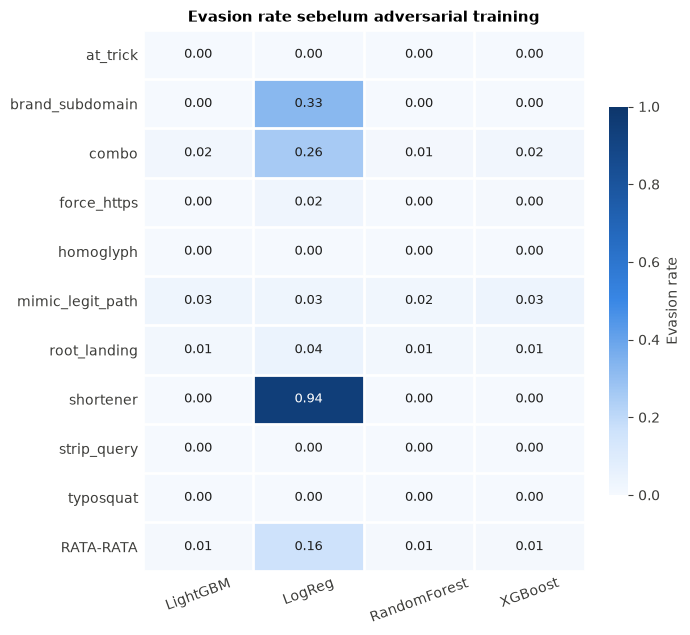

model,LightGBM,LogReg,RandomForest,XGBoost
attack,,,,
at_trick,0.0000,0.0000,0.0000,0.0000
brand_subdomain,0.0000,0.3256,0.0000,0.0000
combo,0.0180,0.2554,0.0108,0.0183
force_https,0.0039,0.0239,0.0020,0.0043
homoglyph,0.0001,0.0000,0.0005,0.0000
mimic_legit_path,0.0279,0.0288,0.0233,0.0317
root_landing,0.0120,0.0398,0.0120,0.0121
shortener,0.0000,0.9375,0.0000,0.0000
strip_query,0.0004,0.0016,0.0009,0.0012


In [24]:
tabel2 = ev_base.pivot(index="attack", columns="model", values="evasion_rate").round(4)
tabel2.loc["RATA-RATA"] = tabel2.mean().round(4)
tabel2.to_csv(f"{RES}/tabel2_evasion_rate.csv")

def heatmap(tbl, judul, path):
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(tbl) + 1.5))
    im = ax.imshow(tbl.values, cmap=CMAP_SEQ, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(tbl.shape[1]), tbl.columns, rotation=20)
    ax.set_yticks(range(tbl.shape[0]), tbl.index)
    # garis putih tipis antar sel
    ax.set_xticks(np.arange(-.5, tbl.shape[1]), minor=True)
    ax.set_yticks(np.arange(-.5, tbl.shape[0]), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            v = tbl.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v > 0.5 else "#1f1f1e", fontsize=9)
    cb = fig.colorbar(im, ax=ax, fraction=0.04)
    cb.set_label("Evasion rate"); cb.outline.set_visible(False)
    ax.set_title(judul)
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

heatmap(tabel2, "Evasion rate sebelum adversarial training", f"{FIG}/gambar1_evasion_sebelum.png")
tabel2

## 7. RQ3a — Adversarial training
Setiap URL phishing di data latih diberi satu versi samaran (teknik dipilih acak, seed berbeda dari test), lalu model dilatih ulang. Dievaluasi di data test bersih dan data test yang diserang.

In [25]:
def augment(urls, attack_names, seed):
    rng = random.Random(seed)
    return [ATTACKS[rng.choice(attack_names)](u, rng) for u in urls]

def fit_augmented(attack_names, seed, only=None):
    aug = augment(train_phish_urls, attack_names, seed)
    Xa = pd.concat([X_all.loc[idx_tr], EXTRACT(aug)], ignore_index=True)
    ya = np.concatenate([df.y[idx_tr].values, np.ones(len(aug), dtype=int)])
    ms = make_models(MAIN_SEED)
    if only:
        ms = {only: ms[only]}
    for m in ms.values():
        m.fit(Xa, ya)
    return ms

models_adv = fit_augmented(list(ATTACKS), seed=99)

rows = []
for tag, ms in [("sebelum", models), ("sesudah", models_adv)]:
    for name, m in ms.items():
        proba = m.predict_proba(X_all.loc[idx_te])[:, 1]
        rows.append(dict(kondisi=tag, model=name, **metrics(df.y[idx_te], (proba >= 0.5).astype(int), proba)))
tabel3 = pd.DataFrame(rows).set_index(["model", "kondisi"]).sort_index().round(4)
tabel3.to_csv(f"{RES}/tabel3_clean_sebelum_sesudah.csv")
tabel3

accuracy  precision  recall      f1  roc_auc     fpr
model        kondisi                                                      
LightGBM     sebelum    0.9994     0.9992  0.9998  0.9995   1.0000  0.0013
             sesudah    0.9987     0.9980  0.9999  0.9989   1.0000  0.0035
LogReg       sebelum    0.9955     0.9987  0.9943  0.9964   0.9994  0.0023
             sesudah    0.9922     0.9911  0.9965  0.9938   0.9994  0.0151
RandomForest sebelum    0.9994     0.9992  0.9998  0.9995   1.0000  0.0013
             sesudah    0.9983     0.9973  1.0000  0.9987   1.0000  0.0045
XGBoost      sebelum    0.9996     0.9994  0.9998  0.9996   1.0000  0.0009
             sesudah    0.9985     0.9976  0.9999  0.9988   1.0000  0.0040

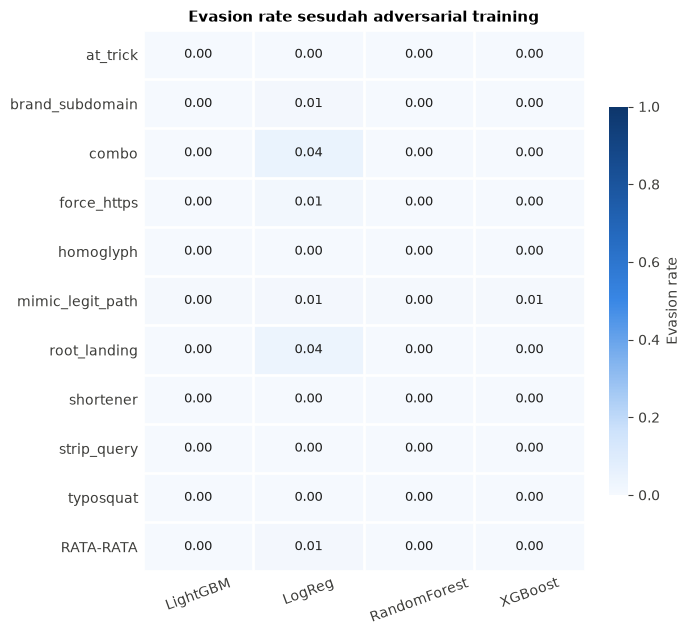

,sebelum,sesudah,penurunan
model,,,
LightGBM,0.0062,0.0009,0.0053
LogReg,0.1613,0.0114,0.1499
RandomForest,0.0050,0.0007,0.0043
XGBoost,0.0068,0.0010,0.0058


In [26]:
ev_adv, _ = evasion_table(models_adv, seed_offset=500)   # seed serangan beda dari augmentasi
tabel4 = ev_adv.pivot(index="attack", columns="model", values="evasion_rate").round(4)
tabel4.loc["RATA-RATA"] = tabel4.mean().round(4)
tabel4.to_csv(f"{RES}/tabel4_evasion_sesudah.csv")
heatmap(tabel4, "Evasion rate sesudah adversarial training", f"{FIG}/gambar2_evasion_sesudah.png")

ringkas = pd.DataFrame({"sebelum": tabel2.loc["RATA-RATA"], "sesudah": tabel4.loc["RATA-RATA"]})
ringkas["penurunan"] = ringkas["sebelum"] - ringkas["sesudah"]
ringkas.round(4).to_csv(f"{RES}/tabel4b_ringkas_evasion.csv")
ringkas.round(4)

## 7b. RQ2b — Penyerang adaptif
Serangan di atas diterapkan "buta" (satu teknik, sekali). Penyerang yang lebih realistis mencoba **semua rantai penyamaran**
(10 teknik tunggal + semua pasangan berurutan dua teknik), **menanyakan skor ke model**, lalu memakai kandidat dengan
probabilitas phishing terendah. Ini serangan *black-box* berbasis kueri dengan anggaran kueri = jumlah rantai per URL.
Model dianggap berhasil diakali bila skor kandidat terbaik < 0,5 pada URL yang awalnya terdeteksi.

In [27]:
CHAINS = candidate_chains(ATTACKS)
chain_names = [" + ".join(c) for c in CHAINS]
cand_urls, owner, chain_id = generate_candidates(test_phish_urls, ATTACKS, CHAINS, seed=4242)
t = time.perf_counter()
X_cand = EXTRACT(cand_urls)
print(f"{len(CHAINS)} rantai x {len(test_phish_urls)} URL = {len(cand_urls)} kandidat "
      f"(ekstraksi {time.perf_counter() - t:.0f} detik)")

def adaptive_eval(m):
    det = m.predict(X_tp) == 1
    p = m.predict_proba(X_cand)[:, 1]
    best = (pd.DataFrame({"owner": owner, "p": p, "chain": chain_id})
              .sort_values("p", kind="stable").drop_duplicates("owner")
              .set_index("owner").sort_index())
    lolos = (best["p"].values < 0.5) & det
    hasil = dict(evasion_adaptif=lolos.sum() / max(det.sum(), 1),
                 median_skor_terbaik=float(np.median(best["p"].values[det])) if det.any() else np.nan)
    return hasil, best, lolos

rows, menang = [], {}
for tag, ms in [("tanpa_adv", models), ("adv_acak", models_adv)]:
    for name, m in ms.items():
        r, best, lolos = adaptive_eval(m)
        rows.append(dict(model=name, kondisi=tag, **r))
        if tag == "tanpa_adv":
            menang[name] = pd.Series([chain_names[c] for c in best["chain"].values[lolos]], dtype=object).value_counts()
tabel9 = pd.DataFrame(rows)

tabel10 = pd.DataFrame(menang).fillna(0).astype(int)
if len(tabel10):
    tabel10 = tabel10.loc[tabel10.sum(axis=1).sort_values(ascending=False).index].head(10)
tabel10.to_csv(f"{RES}/tabel10_rantai_paling_berhasil.csv")
print("Rantai penyamaran yang paling sering berhasil (model tanpa adversarial training):")
display(tabel10)
tabel9.set_index(["model", "kondisi"]).sort_index().round(4)

65 rantai x 12699 URL = 825435 kandidat (ekstraksi 51 detik)
Rantai penyamaran yang paling sering berhasil (model tanpa adversarial training):


,LogReg,RandomForest,XGBoost,LightGBM
force_https + brand_subdomain,5247,0,16,19
brand_subdomain + force_https,4191,0,5,9
force_https + root_landing,1822,272,214,132
force_https + mimic_legit_path,9,569,869,913
mimic_legit_path + force_https,11,539,837,942
brand_subdomain + root_landing,372,0,0,0
root_landing + brand_subdomain,363,0,0,0
brand_subdomain + mimic_legit_path,236,0,12,19
mimic_legit_path + brand_subdomain,224,0,13,20
mimic_legit_path + typosquat,0,40,91,85


evasion_adaptif  median_skor_terbaik
model        kondisi                                        
LightGBM     adv_acak            0.0613               1.0000
             tanpa_adv           0.2001               0.9999
LogReg       adv_acak            0.2841               0.8985
             tanpa_adv           0.9996               0.0000
RandomForest adv_acak            0.0468               1.0000
             tanpa_adv           0.1392               0.8600
XGBoost      adv_acak            0.0610               0.9999
             tanpa_adv           0.1915               0.9890

## 7c. RQ3c — Adversarial training adaptif
Untuk tiap model, URL phishing data latih (maks. 20.000, diambil acak) diserang secara adaptif terhadap model itu sendiri,
kandidat terbaiknya ditambahkan ke data latih, lalu model dilatih ulang. Penyerang adaptif kemudian menyerang model baru
(memilih ulang kandidat terbaik menurut model baru, dengan URL test dan seed berbeda dari data latih).

In [28]:
N_AUG_ADAPTIF = min(20000, len(train_phish_urls))
aug_src = random.Random(MAIN_SEED).sample(train_phish_urls, N_AUG_ADAPTIF)
c_urls, c_owner, _ = generate_candidates(aug_src, ATTACKS, CHAINS, seed=99)
t = time.perf_counter()
X_c = EXTRACT(c_urls)
print(f"Kandidat latih: {len(c_urls)} (ekstraksi {time.perf_counter() - t:.0f} detik)")

models_adapt = {}
for name, m0 in models.items():
    p = m0.predict_proba(X_c)[:, 1]
    pick = (pd.DataFrame({"o": c_owner, "p": p}).reset_index()
              .sort_values("p", kind="stable").drop_duplicates("o")["index"].values)
    Xa = pd.concat([X_all.loc[idx_tr], X_c.iloc[pick]], ignore_index=True)
    ya = np.concatenate([df.y[idx_tr].values, np.ones(len(pick), dtype=int)])
    m = make_models(MAIN_SEED)[name]
    m.fit(Xa, ya)
    models_adapt[name] = m

rows = []
for name, m in models_adapt.items():
    r, _, _ = adaptive_eval(m)
    rows.append(dict(model=name, kondisi="adv_adaptif", **r))
tabel9 = pd.concat([tabel9, pd.DataFrame(rows)], ignore_index=True)
tabel9 = tabel9.set_index(["model", "kondisi"]).sort_index().round(4)
tabel9.to_csv(f"{RES}/tabel9_evasion_adaptif.csv")

rows = []
for tag, ms in [("tanpa_adv", models), ("adv_acak", models_adv), ("adv_adaptif", models_adapt)]:
    for name, m in ms.items():
        proba = m.predict_proba(X_all.loc[idx_te])[:, 1]
        rows.append(dict(model=name, kondisi=tag, **metrics(df.y[idx_te], (proba >= 0.5).astype(int), proba)))
tabel11 = pd.DataFrame(rows).set_index(["model", "kondisi"]).sort_index().round(4)
tabel11.to_csv(f"{RES}/tabel11_clean_tiga_kondisi.csv")
print("Evasion rate penyerang adaptif:")
display(tabel9)
print("Performa di data test bersih (cek adversarial training tidak merusak):")
tabel11

Kandidat latih: 1300000 (ekstraksi 92 detik)
Evasion rate penyerang adaptif:


evasion_adaptif  median_skor_terbaik
model        kondisi                                          
LightGBM     adv_acak              0.0613               1.0000
             adv_adaptif           0.0156               1.0000
             tanpa_adv             0.2001               0.9999
LogReg       adv_acak              0.2841               0.8985
             adv_adaptif           0.9922               0.1364
             tanpa_adv             0.9996               0.0000
RandomForest adv_acak              0.0468               1.0000
             adv_adaptif           0.0050               0.9900
             tanpa_adv             0.1392               0.8600
XGBoost      adv_acak              0.0610               0.9999
             adv_adaptif           0.0157               0.9999
             tanpa_adv             0.1915               0.9890

Performa di data test bersih (cek adversarial training tidak merusak):


accuracy  precision  recall      f1  roc_auc     fpr
model        kondisi                                                          
LightGBM     adv_acak       0.9987     0.9980  0.9999  0.9989   1.0000  0.0035
             adv_adaptif    0.9980     0.9968  1.0000  0.9984   1.0000  0.0055
             tanpa_adv      0.9994     0.9992  0.9998  0.9995   1.0000  0.0013
LogReg       adv_acak       0.9922     0.9911  0.9965  0.9938   0.9994  0.0151
             adv_adaptif    0.9890     0.9865  0.9962  0.9913   0.9991  0.0231
             tanpa_adv      0.9955     0.9987  0.9943  0.9964   0.9994  0.0023
RandomForest adv_acak       0.9983     0.9973  1.0000  0.9987   1.0000  0.0045
             adv_adaptif    0.9973     0.9958  1.0000  0.9979   0.9999  0.0072
             tanpa_adv      0.9994     0.9992  0.9998  0.9995   1.0000  0.0013
XGBoost      adv_acak       0.9985     0.9976  0.9999  0.9988   1.0000  0.0040
             adv_adaptif    0.9981     0.9971  0.9998  0.9985   1.0000  0.0049
             tanpa_adv      0.9996     0.9994  0.9998  0.9996   1.0000  0.0009

## 8. RQ3b — Leave-one-attack-out (LightGBM)
Model dilatih dengan augmentasi semua teknik kecuali satu, lalu diuji pada teknik yang disisihkan. Ini menguji apakah ketahanan berlaku untuk serangan yang belum pernah dilihat.

In [29]:
base_lgb = ev_base[ev_base.model == "LightGBM"].set_index("attack")["evasion_rate"]
names = [a for a in ATTACKS if a != "combo"]
rows = []
for held in names:
    m = fit_augmented([a for a in names if a != held], seed=123, only="LightGBM")["LightGBM"]
    adv = apply_attack(test_phish_urls, ATTACKS[held], seed=777)
    det = m.predict(X_tp) == 1
    pa = m.predict(EXTRACT(adv))
    rows.append(dict(teknik_disisihkan=held, evasion_tanpa_adv=base_lgb[held],
                     evasion_loao=((pa == 0) & det).sum() / max(det.sum(), 1)))
tabel5 = pd.DataFrame(rows).round(4)
tabel5.to_csv(f"{RES}/tabel5_leave_one_attack_out.csv", index=False)
tabel5

,teknik_disisihkan,evasion_tanpa_adv,evasion_loao
0,force_https,0.0039,0.0013
1,root_landing,0.0120,0.0062
2,typosquat,0.0001,0.0001
3,homoglyph,0.0001,0.0000
4,brand_subdomain,0.0000,0.0000
5,at_trick,0.0000,0.0000
6,strip_query,0.0004,0.0000
7,mimic_legit_path,0.0279,0.0198
8,shortener,0.0000,0.0000


## 9. RQ4a — SHAP (LightGBM, sebelum vs sesudah adversarial training)

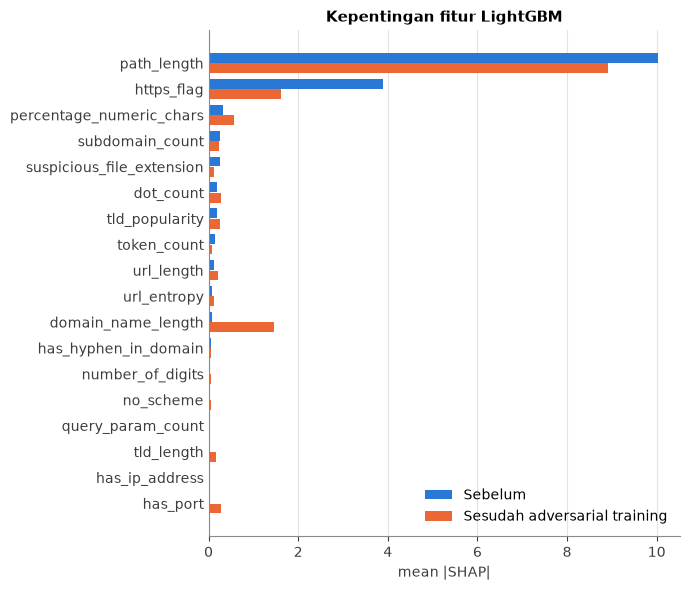

,sebelum,sesudah
path_length,10.0188,8.9148
https_flag,3.8871,1.6207
percentage_numeric_chars,0.3314,0.5771
subdomain_count,0.2509,0.2420
suspicious_file_extension,0.2455,0.1258
dot_count,0.1915,0.2887
tld_popularity,0.1811,0.2605
token_count,0.1354,0.0779
url_length,0.1303,0.2144
url_entropy,0.0881,0.1283


In [30]:
import shap
sample = X_all.loc[idx_te].sample(min(2000, len(idx_te)), random_state=MAIN_SEED)

def mean_abs_shap(model, X):
    sv = shap.TreeExplainer(model).shap_values(X)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, 1]
    return pd.Series(np.abs(sv).mean(0), index=X.columns)

tabel6 = pd.DataFrame({"sebelum": mean_abs_shap(models["LightGBM"], sample),
                       "sesudah": mean_abs_shap(models_adv["LightGBM"], sample)}).sort_values("sebelum")
tabel6.round(4).to_csv(f"{RES}/tabel6_shap.csv")

fig, ax = plt.subplots(figsize=(7, 6))
y = np.arange(len(tabel6))
ax.barh(y + 0.2, tabel6["sebelum"], height=0.38, color=WARNA_SEBELUM, label="Sebelum")
ax.barh(y - 0.2, tabel6["sesudah"], height=0.38, color=WARNA_SESUDAH, label="Sesudah adversarial training")
ax.set_yticks(y, tabel6.index); ax.set_xlabel("mean |SHAP|"); ax.legend(loc="lower right")
ax.xaxis.grid(True, color="#e4e3df", linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.set_title("Kepentingan fitur LightGBM")
fig.tight_layout(); fig.savefig(f"{FIG}/gambar3_shap.png", dpi=300); plt.show()
tabel6.sort_values("sebelum", ascending=False).round(4)

## 10. RQ4b — Uji jalan pintas domain (split per domain)
Domain yang sama tidak boleh muncul di train dan test sekaligus. Kalau F1 turun jauh dibanding split acak, model banyak menghafal domain.

In [31]:
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=MAIN_SEED)
g_tr, g_te = next(gss.split(X_all, df.y, groups=df["domain"]))
rows = []
for name, m in make_models(MAIN_SEED).items():
    m.fit(X_all.iloc[g_tr], df.y.iloc[g_tr])
    proba = m.predict_proba(X_all.iloc[g_te])[:, 1]
    r = metrics(df.y.iloc[g_te], (proba >= 0.5).astype(int), proba)
    acak = baseline[(baseline.seed == MAIN_SEED) & (baseline.model == name)].iloc[0]
    rows.append(dict(model=name, f1_split_acak=acak["f1"], f1_split_domain=r["f1"],
                     fpr_split_acak=acak["fpr"], fpr_split_domain=r["fpr"]))
tabel7 = pd.DataFrame(rows).round(4)
tabel7.to_csv(f"{RES}/tabel7_split_domain.csv", index=False)
print(f"Test split domain: {len(g_te)} URL, {df['domain'].iloc[g_te].nunique()} domain")
tabel7

Test split domain: 19487 URL, 12300 domain


,model,f1_split_acak,f1_split_domain,fpr_split_acak,fpr_split_domain
0,LogReg,0.9964,0.9930,0.0023,0.0179
1,RandomForest,0.9995,0.9968,0.0013,0.0101
2,XGBoost,0.9996,0.9977,0.0009,0.0067
3,LightGBM,0.9995,0.9982,0.0013,0.0053


## 11. RQ5 — Replikasi vs terkoreksi
Jalankan sel ini setelah notebook dijalankan untuk kedua set fitur.

In [32]:
sets = [s for s in ["replikasi", "terkoreksi"] if os.path.exists(f"results/{s}/tabel9_evasion_adaptif.csv")]
if len(sets) < 2:
    print("Belum lengkap. Set yang sudah dijalankan:", sets)
else:
    rows = []
    for s in sets:
        t1 = pd.read_csv(f"results/{s}/tabel1_baseline.csv", header=[0, 1], index_col=0)
        ev = pd.read_csv(f"results/{s}/tabel4b_ringkas_evasion.csv", index_col=0)
        t7 = pd.read_csv(f"results/{s}/tabel7_split_domain.csv", index_col="model")
        t9 = pd.read_csv(f"results/{s}/tabel9_evasion_adaptif.csv", index_col=[0, 1])
        for m in t1.index:
            rows.append(dict(model=m, set_fitur=s,
                             f1=t1.loc[m, ("f1", "mean")], fpr=t1.loc[m, ("fpr", "mean")],
                             evasion_sebelum=ev.loc[m, "sebelum"], evasion_sesudah=ev.loc[m, "sesudah"],
                             adaptif_tanpa_adv=t9.loc[(m, "tanpa_adv"), "evasion_adaptif"],
                             adaptif_adv_adaptif=t9.loc[(m, "adv_adaptif"), "evasion_adaptif"],
                             f1_split_domain=t7.loc[m, "f1_split_domain"]))
    tabel8 = pd.DataFrame(rows).set_index(["model", "set_fitur"]).sort_index().round(4)
    tabel8.to_csv("results/tabel8_replikasi_vs_terkoreksi.csv")
    display(tabel8)

f1     fpr  evasion_sebelum  evasion_sesudah  \
model        set_fitur                                                      
LightGBM     replikasi   0.9994  0.0012           0.0068           0.0010   
             terkoreksi  0.9995  0.0013           0.0062           0.0009   
LogReg       replikasi   0.9974  0.0020           0.1182           0.0045   
             terkoreksi  0.9961  0.0026           0.1613           0.0114   
RandomForest replikasi   0.9995  0.0016           0.0071           0.0006   
             terkoreksi  0.9994  0.0017           0.0050           0.0007   
XGBoost      replikasi   0.9996  0.0012           0.0070           0.0010   
             terkoreksi  0.9996  0.0012           0.0068           0.0010   

                         adaptif_tanpa_adv  adaptif_adv_adaptif  \
model        set_fitur                                            
LightGBM     replikasi              0.2092               0.0134   
             terkoreksi             0.2001               0.0156   
LogReg       replikasi              1.0000               0.0709   
             terkoreksi             0.9996               0.9922   
RandomForest replikasi              0.1505               0.0051   
             terkoreksi             0.1392               0.0050   
XGBoost      replikasi              0.2030               0.0212   
             terkoreksi             0.1915               0.0157   

                         f1_split_domain  
model        set_fitur                    
LightGBM     replikasi            0.9970  
             terkoreksi           0.9982  
LogReg       replikasi            0.9959  
             terkoreksi           0.9930  
RandomForest replikasi            0.9958  
             terkoreksi           0.9968  
XGBoost      replikasi            0.9981  
             terkoreksi           0.9977

## 12. Peta hasil ke artikel
| Bagian artikel | Ambil dari |
|---|---|
| Metode: dataset & pembersihan | output sel 1, `tabel0_konsentrasi_domain.csv` |
| Metode: fitur | `features.py`, `cek_fitur_vs_bawaan.csv` |
| Metode: teknik serangan | `perturb.py`, contoh URL di sel 6 |
| Hasil RQ1 | `tabel1_baseline.csv` |
| Hasil RQ2 | `tabel2_evasion_rate.csv`, `gambar1_evasion_sebelum.png` |
| Hasil RQ3 | `tabel3`, `tabel4`, `tabel4b`, `tabel5`, `gambar2_evasion_sesudah.png` |
| Hasil RQ2b/RQ3c (adaptif) | `tabel9_evasion_adaptif.csv`, `tabel10_rantai_paling_berhasil.csv`, `tabel11_clean_tiga_kondisi.csv` |
| Hasil RQ4 | `tabel6_shap.csv`, `gambar3_shap.png`, `tabel7_split_domain.csv` |
| Hasil RQ5 | `results/tabel8_replikasi_vs_terkoreksi.csv` |

Tabel 0–7 ada di `results/replikasi/` dan `results/terkoreksi/`.

**Keterbatasan yang jujur ditulis:** serangan bersifat *black-box* berbasis aturan (penyerang adaptif hanya memilih dari 65 rantai penyamaran, bukan optimasi gradien); fitur hanya leksikal
(tanpa konten halaman/WHOIS); homoglyph memakai karakter ASCII (bukan Unicode/punycode); hanya satu dataset.